# BikeNodePlanner–OSM overlap

In [47]:
# Run once if your environment is missing packages:
#%pip install geopandas osmnx matplotlib pandas shapely pyogrio
#pixi add pyrosm pyarrow

## Setup

In [48]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
import shapely
from IPython.display import display
from shapely.geometry import box
import requests
from pyrosm import OSM

working_dir = Path.cwd().resolve()

PROJECT_ROOT = working_dir.parent if working_dir.name == "osm_data_exploration" else working_dir

DENMARK_OSM_DIR = PROJECT_ROOT / "osm_data_exploration/outputs/denmark"
PBF_PATH = DENMARK_OSM_DIR / "denmark-latest.osm.pbf"

DENMARK_OSM_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

EXTRACTION_MARGIN_M = 5_000
TOLERANCE_M = 20

## Load OSM Bike network

Tag information for Denmark: [LINK](https://taginfo.geofabrik.de/europe:denmark/)

In [ ]:
PBF_URL = ("https://download.geofabrik.de/europe/denmark-latest.osm.pbf")

if not PBF_PATH.exists():
    print("Downloading Denmark OSM data...")
    print("This can take several minutes.")

    temporary_path = Path(str(PBF_PATH) + ".download")

    with requests.get(PBF_URL, stream=True, timeout=120) as response:
        response.raise_for_status()
        total_bytes = int(response.headers.get("content-length", 0))
        downloaded_bytes = 0

        with temporary_path.open("wb") as file:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if not chunk:
                    continue

                file.write(chunk)
                downloaded_bytes += len(chunk)

                if total_bytes:
                    percentage = (100 * downloaded_bytes / total_bytes)
                    print(f"\rDownloaded: {percentage:5.1f}%", end="")

    temporary_path.replace(PBF_PATH)
    print("\nDownload completed.")

else:
    print("Using existing Denmark OSM file.")

print("OSM file:", PBF_PATH)

Using existing Denmark OSM file.
OSM file: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/denmark/denmark-latest.osm.pbf


## Functions for plotting

In [ ]:
def plot_bicycle_networks(
    sample,
    bike_loops_edges,
    bike_loops_nodes,
    bike_loops_bbox_gdf,
    osm_edges,
    output_dir=None,
):
    """Plot the OSM extraction and BikeNodePlanner network."""
    fig, ax = plt.subplots(figsize=(8, 8), facecolor="#fffffb")

    osm_edges.plot(
        ax=ax,
        color="#c8cdd2",
        linewidth=0.3,
        alpha=0.6,
        label="OSM bicycle network",
        zorder=1,
    )

    bike_loops_edges.plot(
        ax=ax,
        color="#16855b",
        linewidth=1.2,
        label="Bike loop network",
        zorder=2,
    )

    bike_loops_nodes.plot(
        ax=ax,
        color="#172b4d",
        markersize=3,
        label="Bike loop nodes",
        zorder=3,
    )

    bike_loops_bbox_gdf.boundary.plot(
        ax=ax,
        color="#d94841",
        linewidth=1,
        linestyle="--",
        label="Extraction boundary",
        zorder=4,
    )

    ax.set_title(f"{sample.title()} bicycle networks")

    # Use the extraction boundary as the plot extent
    minx, miny, maxx, maxy = (bike_loops_bbox_gdf.total_bounds)

    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)

    ax.margins(0)
    ax.legend(loc="lower left")
    ax.set_axis_off()
    ax.set_aspect("equal")

    fig.tight_layout(pad=0.2)

    # Save when an output directory is provided
    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        plot_path = (output_dir / f"{sample}_bicycle_networks.png")

        fig.savefig(
            plot_path,
            dpi=240,
            bbox_inches="tight",
            pad_inches=0.05,
        )

        print("Saved plot:", plot_path)

    plt.show()
    return fig, ax

In [ ]:
def plot_overlap_results(
    sample,
    tolerance_m,
    output_dir,
    bike_loops_edges,
    bike_loops_nodes,
    osm_edges,
    bike_loops_overlap,
    matched_edges,
    unmatched_edges,
    plot_padding_m=1_000,
):
    """Calculate, print, plot and save network-overlap results."""

    # Calculate results
    total_length_m = bike_loops_overlap["bike_loop_length_m"].sum()
    matched_length_m = bike_loops_overlap["matched_length_m"].sum()
    unmatched_length_m = bike_loops_overlap["unmatched_length_m"].sum()

    coverage_pct = (
        100 * matched_length_m / total_length_m
        if total_length_m > 0
        else np.nan
    )

    print(f"Bike-loop length: {total_length_m / 1000:,.2f} km")
    print(f"Matched length: {matched_length_m / 1000:,.2f} km")
    print(f"Unmatched length: {unmatched_length_m / 1000:,.2f} km")
    print(f"Coverage: {coverage_pct:.2f}%")

    # Plot results
    fig, ax = plt.subplots(figsize=(8, 8), facecolor="#f7f7f5")

    osm_edges.plot(
        ax=ax,
        color="#c8cdd2",
        linewidth=0.25,
        alpha=0.5,
        zorder=1,
    )

    matched_edges.plot(
        ax=ax,
        color="#16855b",
        linewidth=1.6,
        label="Matched",
        zorder=3,
    )

    if not unmatched_edges.empty:
        unmatched_edges.plot(
            ax=ax,
            color="#d94841",
            linewidth=2.3,
            label="Unmatched",
            zorder=4,
        )

    bike_loops_nodes.plot(
        ax=ax,
        color="#172b4d",
        markersize=4,
        label="Bike-loop nodes",
        zorder=5,
    )

    ax.set_title(
        f"{sample.title()} BikeNodePlanner–OSM overlap ({tolerance_m} m)\n"
        f"{coverage_pct:.2f}% matched · {unmatched_length_m / 1000:.2f} km unmatched"
    )

    # Set plot extent from the bike-loop network
    minx, miny, maxx, maxy = (bike_loops_edges.total_bounds)

    ax.set_xlim(minx - plot_padding_m, maxx + plot_padding_m)
    ax.set_ylim(miny - plot_padding_m, maxy + plot_padding_m)

    ax.margins(0)
    ax.set_axis_off()
    ax.set_aspect("equal")
    ax.legend(loc="lower left")

    fig.tight_layout(pad=0.2)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    plot_path = output_dir / f"{sample}_overlap.png"

    fig.savefig(
        plot_path,
        dpi=240,
        bbox_inches="tight",
        pad_inches=0.05,
    )

    plt.show()

    # Return results for later comparison
    return {
        "sample": sample,
        "tolerance_m": tolerance_m,
        "bike_loop_length_km": total_length_m / 1000,
        "matched_length_km": matched_length_m / 1000,
        "unmatched_length_km": unmatched_length_m / 1000,
        "coverage_pct": coverage_pct,
        "plot_path": plot_path,
    }

# Analyse each area separately

## Bornholm

In [52]:
SAMPLE = "bornholm"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/bornholm/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/bornholm/overlap_clean


In [ ]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 89
Bike loop nodes: 59


In [54]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [ ]:
### Time: ≈ 2 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    print(f"Loaded cached {SAMPLE} OSM bicycle network.")

else:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(
        str(PBF_PATH),
        bounding_box=bike_loops_bbox_wgs84,
    )
    # Pyrosm must scan the full Denmark PBF even though it only returns features inside the Funen bounding box.
    osm_edges = osm_reader.get_network(network_type="cycling")

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    # Keep the columns needed for matching and inspection
    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print("Saved Funen OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Extracting the Funen bicycle network from the Denmark PBF...
Saved Funen OSM bicycle network.
OSM bicycle edges: 107,819
OSM CRS: EPSG:25832


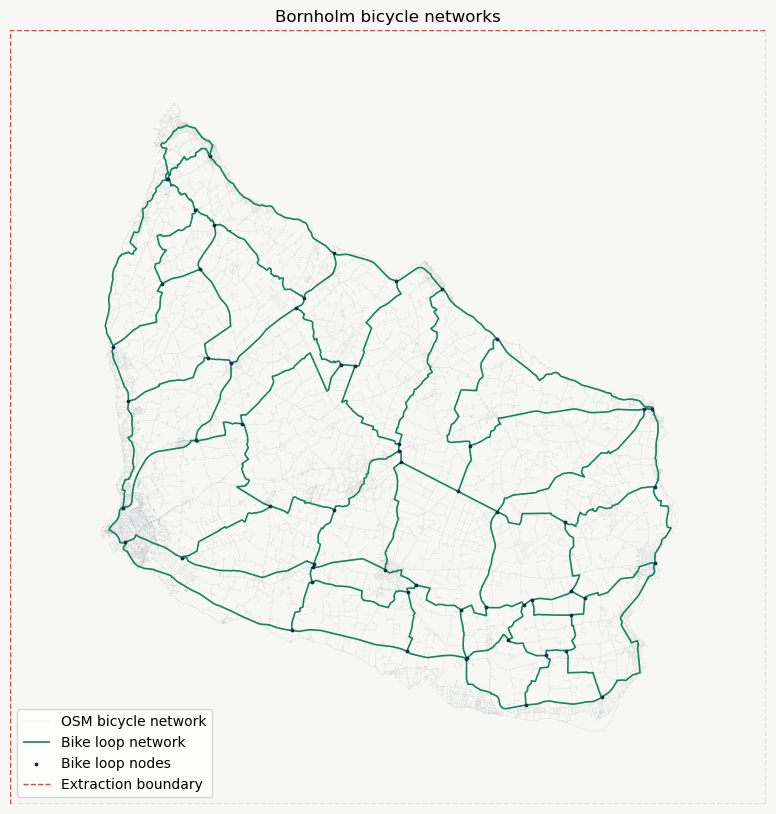

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Bornholm bicycle networks'}>)

In [56]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [57]:
osm_spatial_index = osm_edges.sindex

matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

    else:
        # This union only contains nearby OSM lines
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Matching completed.


In [58]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

Bike-loop length: 375.73 km
Matched length: 374.81 km
Unmatched length: 0.92 km
Coverage: 99.76%


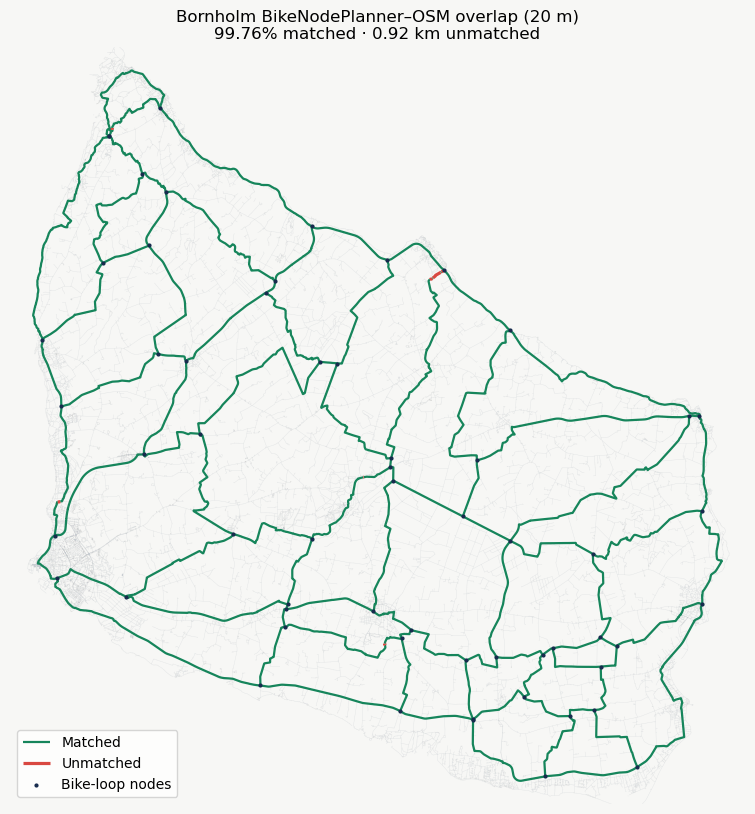

In [59]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

## Fyn

In [60]:
SAMPLE = "funen"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/funen/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/funen/overlap_clean


In [ ]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 1,438
Bike loop nodes: 1,014


In [62]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [ ]:
### Time: ≈ 8 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(
        OSM_EDGES_PATH
    )
    print("Loaded cached Funen OSM bicycle network.")

else:
    print("Extracting the Funen bicycle network from the Denmark PBF...")

    osm_reader = OSM(
        str(PBF_PATH),
        bounding_box=bike_loops_bbox_wgs84,
    )
    # Pyrosm must scan the full Denmark PBF even though it only returns features inside the Funen bounding box.
    osm_edges = osm_reader.get_network(network_type="cycling")

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    # Keep the columns needed for matching and inspection
    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print("Saved Funen OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached Funen OSM bicycle network.
OSM bicycle edges: 719,553
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference Fram

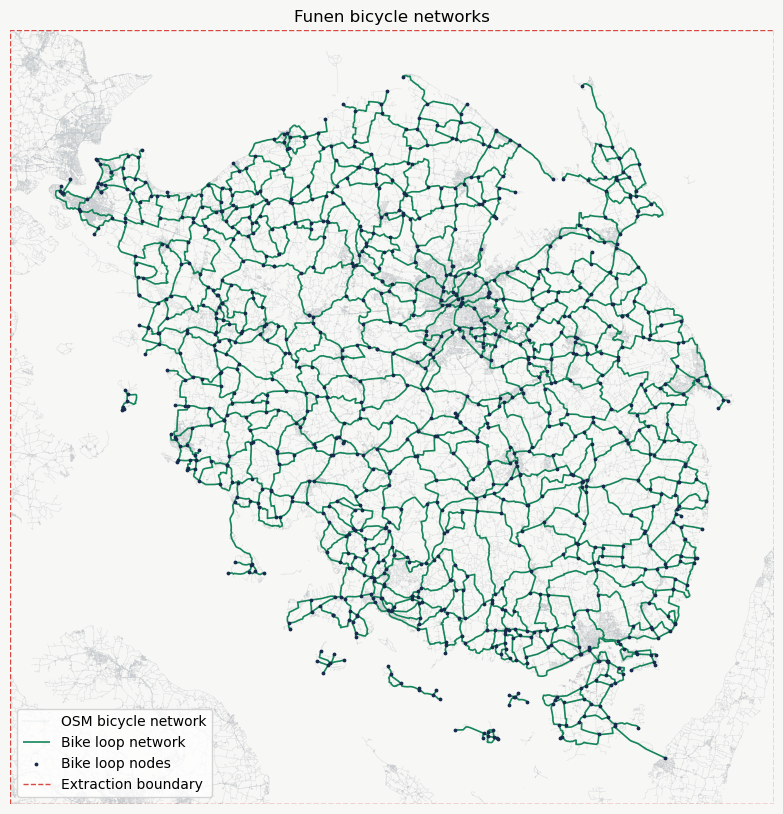

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Funen bicycle networks'}>)

In [64]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [ ]:
osm_spatial_index = osm_edges.sindex

matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []

number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

    else:
        # This union only contains nearby OSM lines
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 1,438 bike-loop edges
Processed 1,000 of 1,438 bike-loop edges
Matching completed.


In [66]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

Bike-loop length: 2,753.85 km
Matched length: 2,726.18 km
Unmatched length: 27.67 km
Coverage: 99.00%


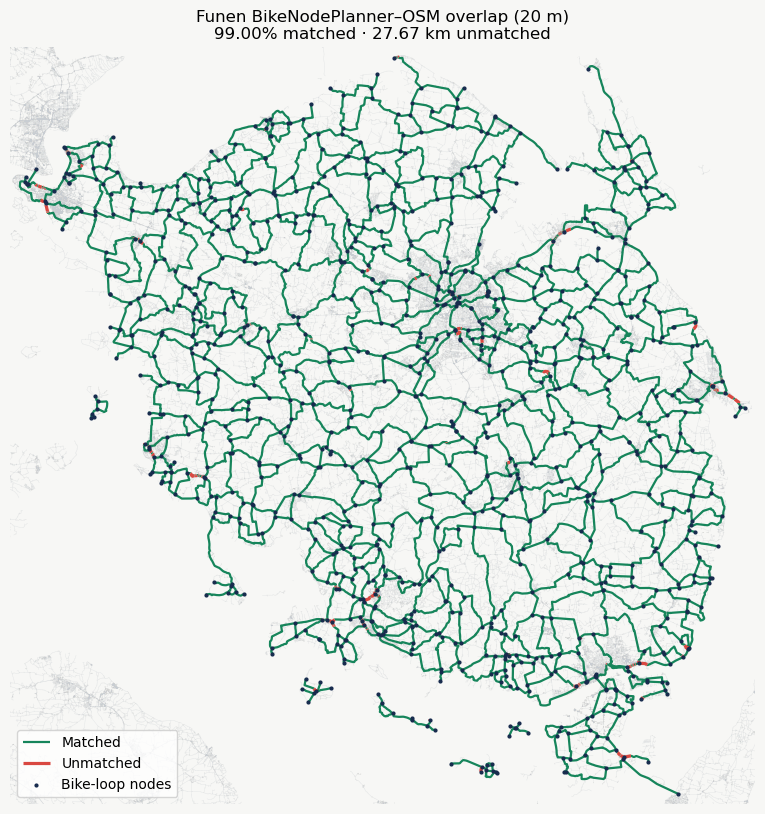

In [67]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

## Jutland

In [69]:
SAMPLE = "jutland"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/jutland/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/jutland/overlap_clean


In [70]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 7,253
Bike loop nodes: 5,006


In [71]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [ ]:
### Time: ≈ 50 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    print(f"Loaded cached {SAMPLE} OSM bicycle network.")

else:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(
        str(PBF_PATH),
        bounding_box=bike_loops_bbox_wgs84,
    )
    # Pyrosm must scan the full Denmark PBF even though it only returns features inside the Funen bounding box.
    osm_edges = osm_reader.get_network(network_type="cycling")

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    # Keep the columns needed for matching and inspection
    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print("Saved Funen OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Extracting the Funen bicycle network from the Denmark PBF...
Saved Funen OSM bicycle network.
OSM bicycle edges: 4,687,424
OSM CRS: EPSG:25832


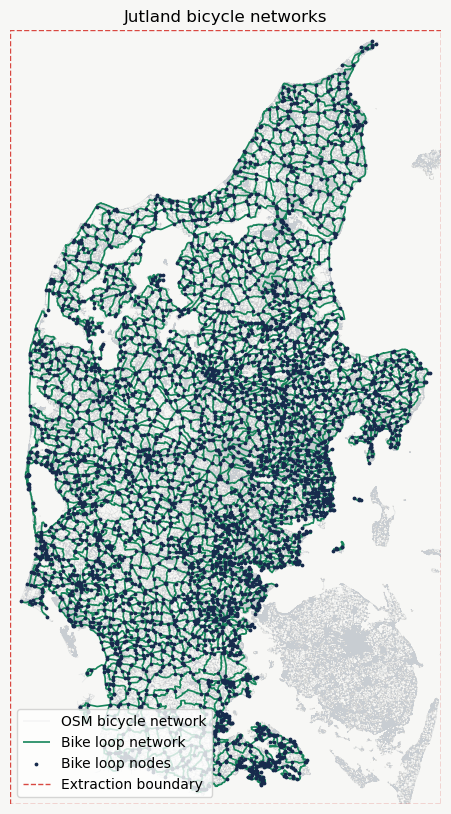

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Jutland bicycle networks'}>)

In [73]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [74]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

    else:
        # This union only contains nearby OSM lines
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 7,253 bike-loop edges
Processed 1,000 of 7,253 bike-loop edges
Processed 1,500 of 7,253 bike-loop edges
Processed 2,000 of 7,253 bike-loop edges
Processed 2,500 of 7,253 bike-loop edges
Processed 3,000 of 7,253 bike-loop edges
Processed 3,500 of 7,253 bike-loop edges
Processed 4,000 of 7,253 bike-loop edges
Processed 4,500 of 7,253 bike-loop edges
Processed 5,000 of 7,253 bike-loop edges
Processed 5,500 of 7,253 bike-loop edges
Processed 6,000 of 7,253 bike-loop edges
Processed 6,500 of 7,253 bike-loop edges
Processed 7,000 of 7,253 bike-loop edges
Matching completed.


In [75]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

Bike-loop length: 18,950.86 km
Matched length: 18,853.13 km
Unmatched length: 97.74 km
Coverage: 99.48%


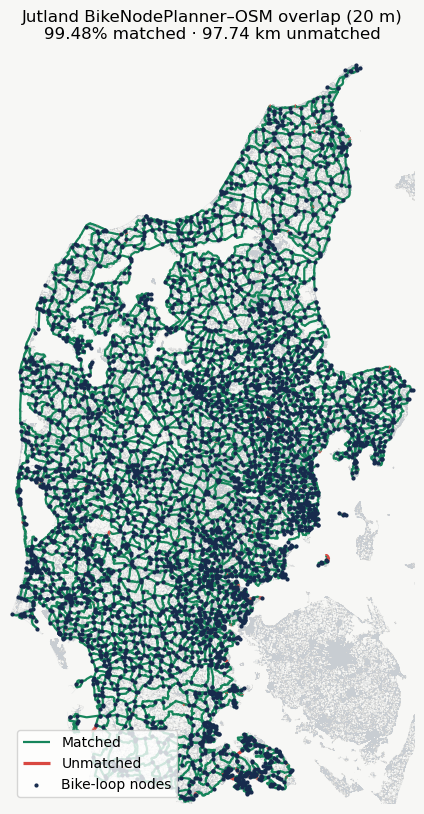

In [76]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

# Lollandfalster

In [77]:
SAMPLE = "lollandfalster"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/lollandfalster/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/lollandfalster/overlap_clean


In [78]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 717
Bike loop nodes: 497


In [79]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [80]:
### Time: ≈ 2 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    print(f"Loaded cached {SAMPLE} OSM bicycle network.")

else:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(
        str(PBF_PATH),
        bounding_box=bike_loops_bbox_wgs84,
    )
    # Pyrosm must scan the full Denmark PBF even though it only returns features inside the Funen bounding box.
    osm_edges = osm_reader.get_network(network_type="cycling")

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    # Keep the columns needed for matching and inspection
    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print("Saved Funen OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Extracting the lollandfalster bicycle network from the Denmark PBF...
Saved Funen OSM bicycle network.
OSM bicycle edges: 191,715
OSM CRS: EPSG:25832


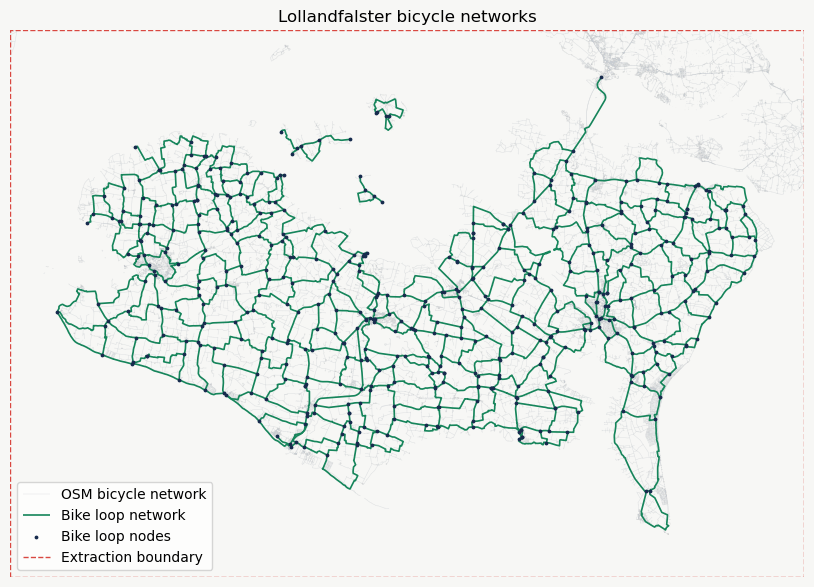

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Lollandfalster bicycle networks'}>)

In [81]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [82]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

    else:
        # This union only contains nearby OSM lines
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 717 bike-loop edges
Matching completed.


In [83]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

Bike-loop length: 1,531.30 km
Matched length: 1,520.98 km
Unmatched length: 10.32 km
Coverage: 99.33%


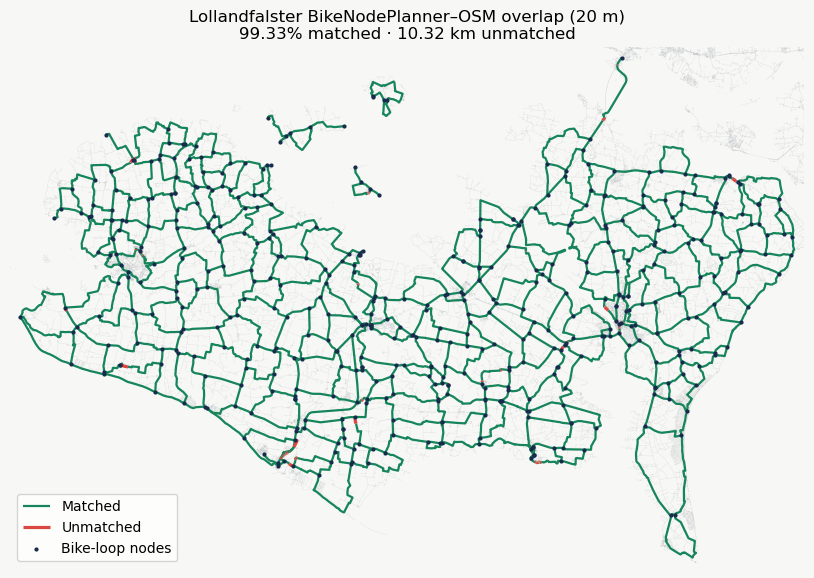

In [84]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

# Longland

In [85]:
SAMPLE = "longland"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/longland/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/longland/overlap_clean


In [86]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 130
Bike loop nodes: 102


In [87]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [ ]:
### Time: ≈ 2-3 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    print(f"Loaded cached {SAMPLE} OSM bicycle network.")

else:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(
        str(PBF_PATH),
        bounding_box=bike_loops_bbox_wgs84,
    )
    # Pyrosm must scan the full Denmark PBF even though it only returns features inside the Funen bounding box.
    osm_edges = osm_reader.get_network(network_type="cycling")

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    # Keep the columns needed for matching and inspection
    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print("Saved Funen OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Extracting the longland bicycle network from the Denmark PBF...
Saved Funen OSM bicycle network.
OSM bicycle edges: 110,367
OSM CRS: EPSG:25832


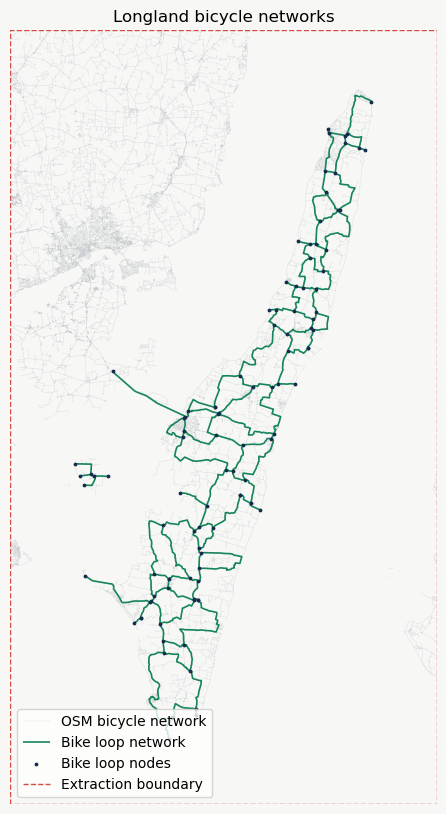

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Longland bicycle networks'}>)

In [89]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [90]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

    else:
        # This union only contains nearby OSM lines
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Matching completed.


In [91]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

Bike-loop length: 269.35 km
Matched length: 269.05 km
Unmatched length: 0.30 km
Coverage: 99.89%


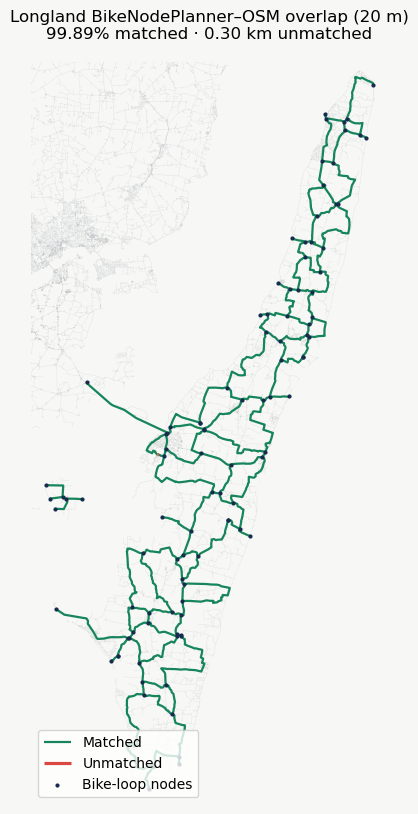

In [92]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)

# Zealand

In [93]:
SAMPLE = "zealand"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
OUTPUT_DIR = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/overlap_clean"

OSM_EDGES_PATH = PROJECT_ROOT / f"osm_data_exploration/outputs/{SAMPLE}/{SAMPLE}_osm_bike_edges.parquet"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OSM_EDGES_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Output folder:", OUTPUT_DIR)

Project root: /Users/ellenebdrup/Documents/GitHub/bike_safety
Bike loop network directory: /Users/ellenebdrup/Documents/GitHub/bike_safety/bikenwloops/data/input/zealand/network/processed
Output folder: /Users/ellenebdrup/Documents/GitHub/bike_safety/osm_data_exploration/outputs/zealand/overlap_clean


In [94]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges_slope.gpkg")
bike_loops_nodes = gpd.read_file(BIKE_LOOPS_DIR / "nodes.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

bike_loops_nodes = bike_loops_nodes.loc[
    bike_loops_nodes.geometry.notna()
    & ~bike_loops_nodes.geometry.is_empty
].copy()

if bike_loops_edges.crs is None:
    raise ValueError("The bike-loop edges do not have a CRS.")

BIKE_LOOPS_CRS = bike_loops_edges.crs
bike_loops_nodes = bike_loops_nodes.to_crs(BIKE_LOOPS_CRS)

print("Bike loops CRS:", BIKE_LOOPS_CRS)
print(f"Bike loop edges: {len(bike_loops_edges):,}")
print(f"Bike loop nodes: {len(bike_loops_nodes):,}")

Bike loops CRS: EPSG:25832
Bike loop edges: 2,589
Bike loop nodes: 1,809


In [95]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

bike_loops_bbox = box(
    minx - EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M,
    maxx + EXTRACTION_MARGIN_M,
    maxy + EXTRACTION_MARGIN_M,
)

# The bounding box below uses the BikeNodePlanner coordinate system (Bike loops CRS: EPSG:25832) with coordinates measured in metres. 
# This is useful for applying the 5,000-metre margin and performing the 20-metre overlap analysis.
bike_loops_bbox_gdf = gpd.GeoDataFrame(
    geometry=[bike_loops_bbox],
    crs=BIKE_LOOPS_CRS,
)

# WGS84 means the bounding box coordinates have been converted to the standard global longitude/latitude coordinate system, EPSG:4326.
bike_loops_bbox_wgs84 = (
    bike_loops_bbox_gdf
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

### Extract area of interest from OSM data

In [ ]:
### Time: ≈ 17 min
if OSM_EDGES_PATH.exists():
    osm_edges = gpd.read_parquet(OSM_EDGES_PATH)
    print(f"Loaded cached {SAMPLE} OSM bicycle network.")

else:
    print(f"Extracting the {SAMPLE} bicycle network from the Denmark PBF...")

    osm_reader = OSM(
        str(PBF_PATH),
        bounding_box=bike_loops_bbox_wgs84,
    )
    # Pyrosm must scan the full Denmark PBF even though it only returns features inside the Funen bounding box.
    osm_edges = osm_reader.get_network(network_type="cycling")

    osm_edges = osm_edges.loc[
        osm_edges.geometry.notna()
        & ~osm_edges.geometry.is_empty
    ].copy()

    osm_edges = osm_edges.explode(
        index_parts=False,
        ignore_index=True,
    )

    osm_edges = osm_edges.to_crs(BIKE_LOOPS_CRS)

    # Keep the columns needed for matching and inspection
    columns_to_keep = [
        column
        for column in [
            "id",
            "name",
            "highway",
            "geometry",
        ]
        if column in osm_edges.columns
    ]

    osm_edges = osm_edges[columns_to_keep].copy()
    osm_edges.to_parquet(OSM_EDGES_PATH)
    print("Saved Funen OSM bicycle network.")

print(f"OSM bicycle edges: {len(osm_edges):,}")
print("OSM CRS:", osm_edges.crs)

Loaded cached zealand OSM bicycle network.
OSM bicycle edges: 1,835,722
OSM CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "ETRS89 / UTM zone 32N", "base_crs": {"type": "GeographicCRS", "name": "ETRS89", "datum_ensemble": {"name": "European Terrestrial Reference System 1989 ensemble", "members": [{"name": "European Terrestrial Reference Frame 1989"}, {"name": "European Terrestrial Reference Frame 1990"}, {"name": "European Terrestrial Reference Frame 1991"}, {"name": "European Terrestrial Reference Frame 1992"}, {"name": "European Terrestrial Reference Frame 1993"}, {"name": "European Terrestrial Reference Frame 1994"}, {"name": "European Terrestrial Reference Frame 1996"}, {"name": "European Terrestrial Reference Frame 1997"}, {"name": "European Terrestrial Reference Frame 2000"}, {"name": "European Terrestrial Reference Frame 2005"}, {"name": "European Terrestrial Reference Frame 2014"}, {"name": "European Terrestrial Reference 

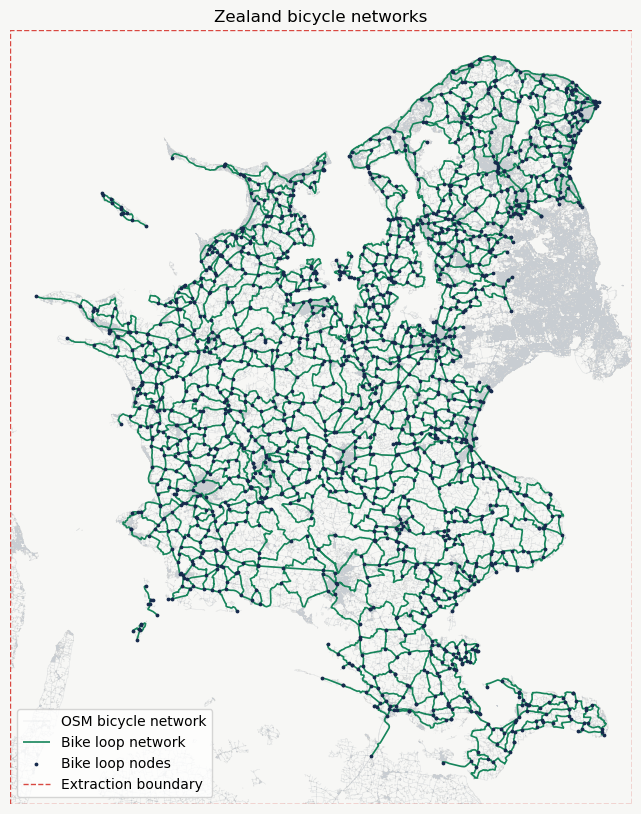

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Zealand bicycle networks'}>)

In [97]:
plot_bicycle_networks(
    sample=SAMPLE,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    bike_loops_bbox_gdf=bike_loops_bbox_gdf,
    osm_edges=osm_edges,
)

### Overlap analysis of the two bike networks

In [98]:
osm_spatial_index = osm_edges.sindex
matched_geometries, unmatched_geometries, matched_lengths, osm_candidate_counts = [], [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Find only OSM lines within the matching tolerance
    candidate_positions = osm_spatial_index.query(
        geometry,
        predicate="dwithin", # This predicate finds geometries that are within a specified distance of the input geometry.
        distance=TOLERANCE_M,
    )

    candidate_positions = np.unique(candidate_positions)
    candidates = osm_edges.iloc[candidate_positions]

    if candidates.empty:
        matched_geometry = shapely.GeometryCollection()
        unmatched_geometry = geometry

    else:
        # This union only contains nearby OSM lines
        local_osm_network = shapely.union_all(candidates.geometry.array)
        local_osm_buffer = local_osm_network.buffer(TOLERANCE_M)
        matched_geometry = geometry.intersection(local_osm_buffer)
        unmatched_geometry = geometry.difference(local_osm_buffer)

    matched_geometries.append(matched_geometry)
    unmatched_geometries.append(unmatched_geometry)
    matched_lengths.append(matched_geometry.length)
    osm_candidate_counts.append(len(candidates))

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 2,589 bike-loop edges
Processed 1,000 of 2,589 bike-loop edges
Processed 1,500 of 2,589 bike-loop edges
Processed 2,000 of 2,589 bike-loop edges
Processed 2,500 of 2,589 bike-loop edges
Matching completed.


In [99]:
bike_loops_overlap = bike_loops_edges.copy()
bike_loops_overlap["bike_loop_length_m"] = (bike_loops_overlap.geometry.length)
bike_loops_overlap["matched_length_m"] = (matched_lengths)
bike_loops_overlap["unmatched_length_m"] = (bike_loops_overlap["bike_loop_length_m"] - bike_loops_overlap["matched_length_m"])
bike_loops_overlap["coverage_pct"] = (100 * bike_loops_overlap["matched_length_m"] / bike_loops_overlap["bike_loop_length_m"])
bike_loops_overlap["osm_candidate_count"] = (osm_candidate_counts)

result_columns = [
    column
    for column in [
        "edge_id",
        "node_start",
        "node_end",
        "bike_loop_length_m",
        "matched_length_m",
        "unmatched_length_m",
        "coverage_pct",
        "osm_candidate_count",
    ]
    if column in bike_loops_overlap.columns
]

matched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=matched_geometries,
    crs=BIKE_LOOPS_CRS,
)

unmatched_edges = gpd.GeoDataFrame(
    bike_loops_overlap[result_columns].copy(),
    geometry=unmatched_geometries,
    crs=BIKE_LOOPS_CRS,
)

matched_edges = matched_edges.loc[~matched_edges.geometry.is_empty].copy()
unmatched_edges = unmatched_edges.loc[~unmatched_edges.geometry.is_empty].copy()

Bike-loop length: 5,519.82 km
Matched length: 5,476.08 km
Unmatched length: 43.74 km
Coverage: 99.21%


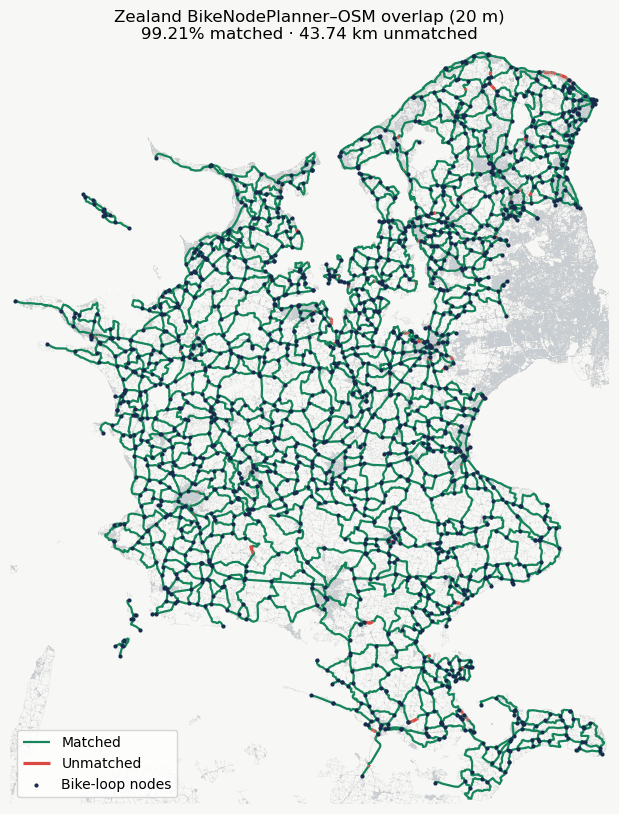

In [100]:
overlap_summary = plot_overlap_results(
    sample=SAMPLE,
    tolerance_m=TOLERANCE_M,
    output_dir=OUTPUT_DIR,
    bike_loops_edges=bike_loops_edges,
    bike_loops_nodes=bike_loops_nodes,
    osm_edges=osm_edges,
    bike_loops_overlap=bike_loops_overlap,
    matched_edges=matched_edges,
    unmatched_edges=unmatched_edges,
)